# plutovizu — Cartes (map)

API chaînable : chaque méthode retourne le graphique, on enchaîne les appels et on termine par `.show()`. Le thème **editorial** est appliqué dès l'import. Fiches détaillées (données attendues, paramètres) dans la [documentation](https://mr-kam.github.io/plutovizu/).

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plutovizu import (Chart, cm, get_fonts, list_themes, set_theme, texture_class,
                       theme_context)

# Taille par défaut d'un graphique : 16 × 10 cm ; cm(largeur, hauteur) pour une autre taille.
# Export (save) : 400 dpi par défaut.

## Map

Cartes avec l'option `map` (`pip install plutovizu[map]`). Coordonnées réelles des villes, valeurs **illustratives**.

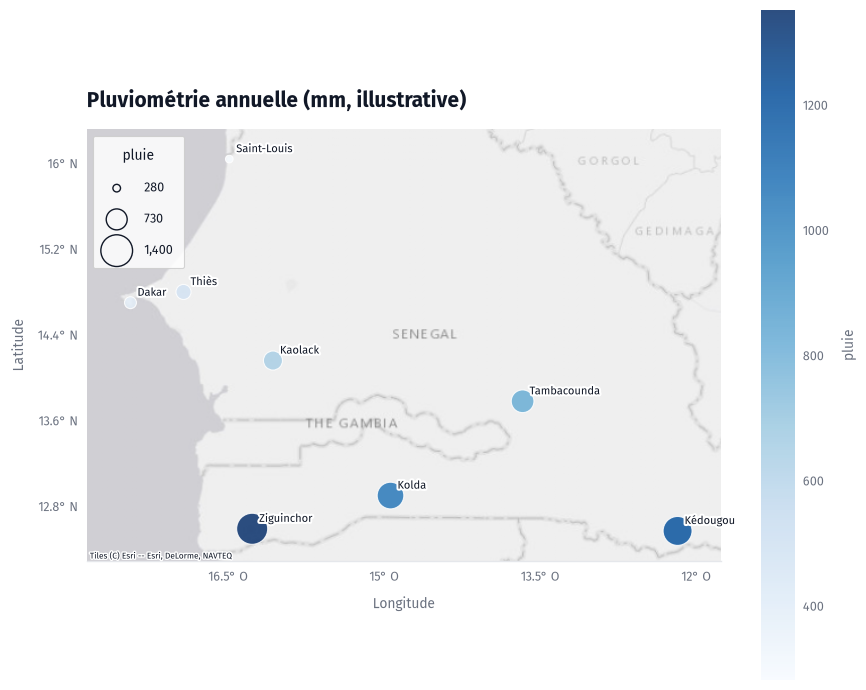

In [2]:
villes = pd.DataFrame({
    'ville': ['Dakar', 'Thiès', 'Saint-Louis', 'Kaolack', 'Tambacounda', 'Kolda', 'Ziguinchor', 'Kédougou'],
    'lon': [-17.44, -16.93, -16.49, -16.07, -13.67, -14.94, -16.27, -12.18],
    'lat': [14.69, 14.79, 16.03, 14.15, 13.77, 12.89, 12.58, 12.56],
    'pluie': [380, 480, 280, 640, 820, 1050, 1350, 1200],
})
(Chart(villes, figsize=(9, 7))
    .map_points('lon', 'lat', value='pluie', size='pluie', labels='ville')
    .title('Pluviométrie annuelle (mm, illustrative)')
    .tight_layout()
    .show())

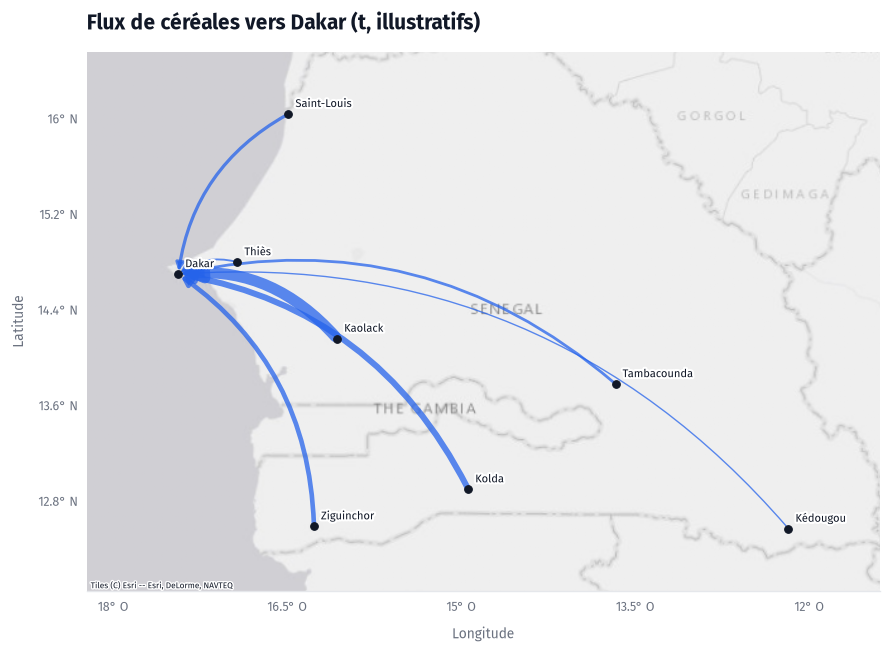

In [3]:
dakar = villes.set_index('ville').loc['Dakar']
flux = (villes[villes['ville'] != 'Dakar']
        .assign(vers='Dakar', lon_d=dakar['lon'], lat_d=dakar['lat'],
                tonnes=[200, 350, 1200, 300, 650, 500, 150]))
(Chart(flux, figsize=(9, 7))
    .flow_map('lon', 'lat', 'lon_d', 'lat_d', weight='tonnes', label_from='ville', label_to='vers')
    .title('Flux de céréales vers Dakar (t, illustratifs)')
    .tight_layout()
    .show())

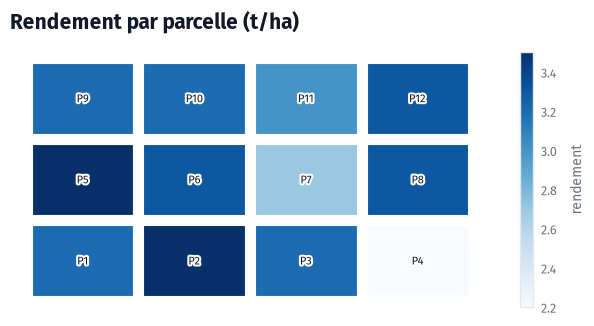

In [4]:
import geopandas as gpd
from shapely.geometry import box

rng = np.random.default_rng(1)
parcelles = gpd.GeoDataFrame(
    {'parcelle': [f'P{i + 1}' for i in range(12)],
     'rendement': (3 + rng.normal(0, 0.6, 12)).round(1)},
    geometry=[box(x * 110, y * 80, x * 110 + 100, y * 80 + 70) for y in range(3) for x in range(4)],
    crs='EPSG:32628')
(Chart(parcelles)
    .choropleth('rendement', labels='parcelle')
    .title('Rendement par parcelle (t/ha)')
    .tight_layout()
    .show())

### Éléments de carte

`north_arrow`, `scale_bar` et `inset_map` se chaînent après n'importe quelle carte ; `map_points(size=...)` ajoute une légende des tailles et les axes sont gradués en degrés.

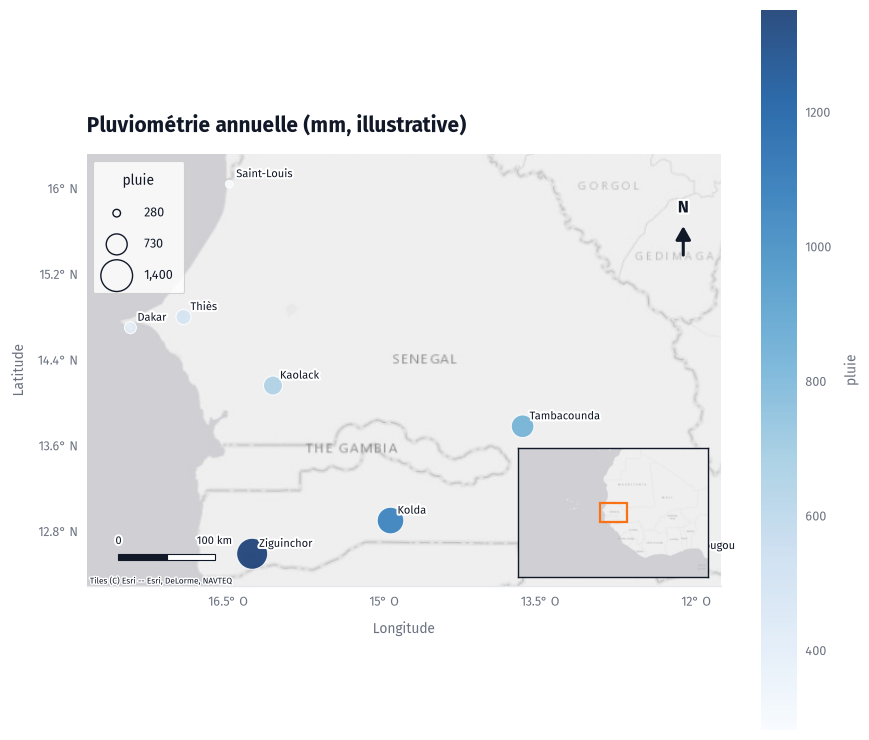

In [5]:
(Chart(villes, figsize=(9, 7.5))
    .map_points('lon', 'lat', value='pluie', size='pluie', labels='ville')
    .north_arrow()
    .scale_bar()
    .inset_map(zoom_out=7)
    .title('Pluviométrie annuelle (mm, illustrative)')
    .tight_layout()
    .show())

### Densité, isolignes et itinéraires (données fictives)

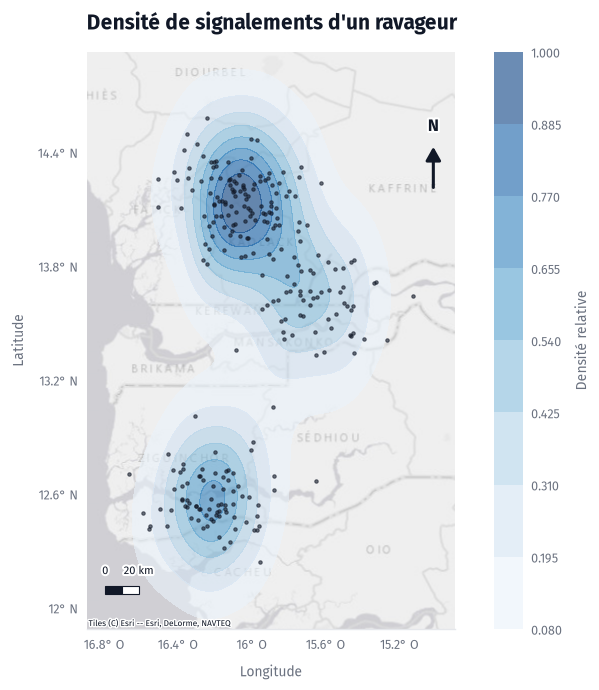

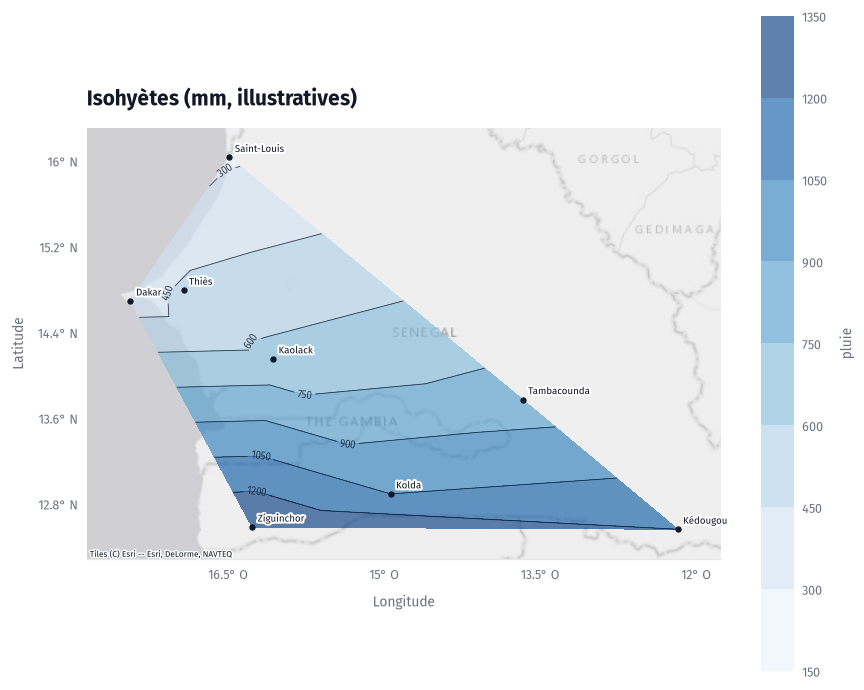

In [6]:
rng = np.random.default_rng(2)
foyers = [(-16.07, 14.15, 120), (-15.6, 13.6, 60), (-16.2, 12.6, 80)]
signalements = pd.DataFrame(np.vstack([np.c_[rng.normal(x, .18, n), rng.normal(y, .15, n)]
                                       for x, y, n in foyers]), columns=['lon', 'lat'])
(Chart(signalements, figsize=(8, 7))
    .density_map('lon', 'lat', show_points=True)
    .title("Densité de signalements d'un ravageur")
    .north_arrow()
    .scale_bar()
    .tight_layout()
    .show())

(Chart(villes, figsize=(9, 7))
    .field_map('lon', 'lat', 'pluie', labels='ville', levels=8)
    .title('Isohyètes (mm, illustratives)')
    .tight_layout()
    .show())

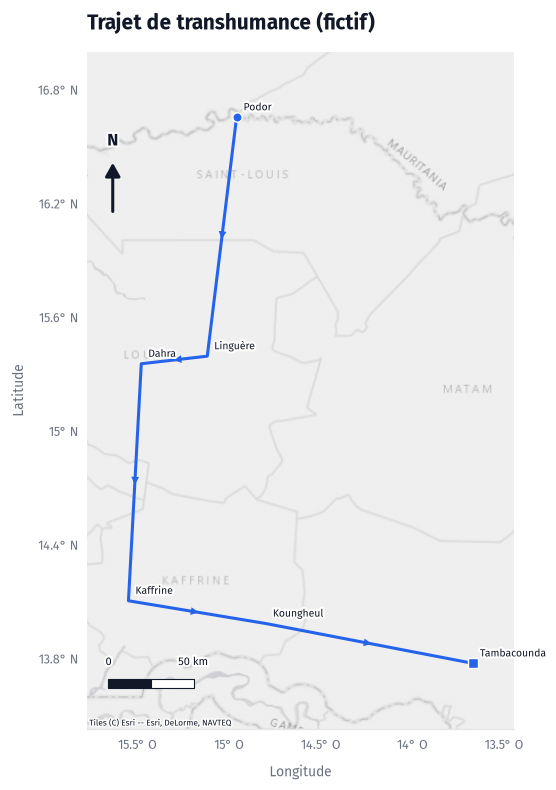

Bornes : [2.2 3.  3.5]


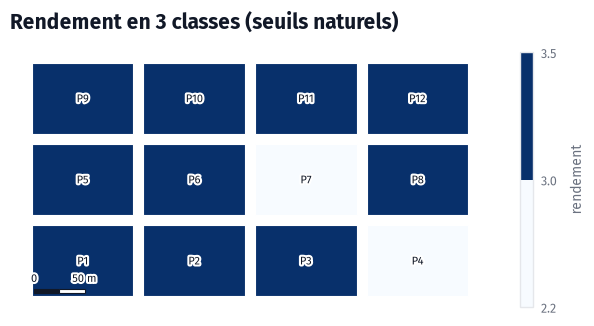

In [7]:
transhumance = pd.DataFrame({
    'etape': ['Podor', 'Linguère', 'Dahra', 'Kaffrine', 'Koungheul', 'Tambacounda'],
    'lon': [-14.96, -15.12, -15.48, -15.55, -14.80, -13.67],
    'lat': [16.65, 15.39, 15.35, 14.10, 13.98, 13.77],
    'jour': [0, 9, 12, 25, 31, 44]})
(Chart(transhumance, figsize=(8, 8))
    .route_map('lon', 'lat', order='jour', labels='etape')
    .title('Trajet de transhumance (fictif)')
    .north_arrow(loc='upper left')
    .scale_bar()
    .tight_layout()
    .show())

chart = (Chart(parcelles)
    .choropleth('rendement', labels='parcelle', scheme='natural', k=3)
    .title('Rendement en 3 classes (seuils naturels)')
    .scale_bar()
    .tight_layout())
print('Bornes :', chart.classes.round(2))
chart.show()